In [30]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [31]:
df = pd.read_csv("/content/Cars_Datasets_2025.csv", encoding='latin1')

In [32]:
df.head()

,Company Names,Cars Names,Engines,CC/Battery Capacity,HorsePower,Total Speed,Performance(0 - 100 )KM/H,Cars Prices,Fuel Types,Seats,Torque
0,FERRARI,SF90 STRADALE,V8,3990 cc,963 hp,340 km/h,2.5 sec,"$1,100,000",plug in hyrbrid,2,800 Nm
1,ROLLS ROYCE,PHANTOM,V12,6749 cc,563 hp,250 km/h,5.3 sec,"$460,000",Petrol,5,900 Nm
2,Ford,KA+,1.2L Petrol,"1,200 cc",70-85 hp,165 km/h,10.5 sec,"$12,000-$15,000",Petrol,5,100 - 140 Nm
3,MERCEDES,GT 63 S,V8,"3,982 cc",630 hp,250 km/h,3.2 sec,"$161,000",Petrol,4,900 Nm
4,AUDI,AUDI R8 Gt,V10,"5,204 cc",602 hp,320 km/h,3.6 sec,"$253,290",Petrol,2,560 Nm


In [33]:
 df.tail()

,Company Names,Cars Names,Engines,CC/Battery Capacity,HorsePower,Total Speed,Performance(0 - 100 )KM/H,Cars Prices,Fuel Types,Seats,Torque
1213,Toyota,Crown Signia,2.5L Hybrid I4,2487 cc,240 hp,180 km/h,7.6 sec,"$43,590  $48,000",Hybrid (Gas + Electric),5,239 Nm
1214,Toyota,4Runner (6th Gen),2.4L Turbo I4 (i-FORCE MAX Hybrid),2393 cc + Battery,326 hp,180 km/h,6.8 sec,"$50,000",Hybrid,7,630 Nm
1215,Toyota,Corolla Cross,2.0L Gas / 2.0L Hybrid,1987 cc / Hybrid batt,169  196 hp,190 km/h,8.0  9.2 sec,"$25,210  $29,135",Gas / Hybrid,5,190  210 Nm
1216,Toyota,C-HR+,1.8L / 2.0L Hybrid,1798 / 1987 cc + batt,140  198 hp,180 km/h,7.9  10.5 sec," 33,000",Hybrid,5,190  205 Nm
1217,Toyota,RAV4 (6th Gen),2.5L Hybrid / Plug-in Hybrid,2487 cc + batt,219  302 hp,200 km/h,6.0  8.1 sec,"$29,000  $43,000",Hybrid / Plug-in,5,221  400 Nm


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Company Names              1218 non-null   object
 1   Cars Names                 1218 non-null   object
 2   Engines                    1218 non-null   object
 3   CC/Battery Capacity        1215 non-null   object
 4   HorsePower                 1218 non-null   object
 5   Total Speed                1218 non-null   object
 6   Performance(0 - 100 )KM/H  1212 non-null   object
 7   Cars Prices                1218 non-null   object
 8   Fuel Types                 1218 non-null   object
 9   Seats                      1218 non-null   object
 10  Torque                     1217 non-null   object
dtypes: object(11)
memory usage: 104.8+ KB


In [35]:
 df.duplicated().sum()

np.int64(4)

In [36]:
df.drop_duplicates(inplace=True)

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.isnull().sum()

,0
Company Names,0
Cars Names,0
Engines,0
CC/Battery Capacity,3
HorsePower,0
Total Speed,0
Performance(0 - 100 )KM/H,6
Cars Prices,0
Fuel Types,0
Seats,0


In [43]:
df['CC/Battery Capacity'] = df['CC/Battery Capacity'].fillna(df['CC/Battery Capacity'].mode()[0])

In [44]:
df['Performance(0 - 100 )KM/H'] = df['Performance(0 - 100 )KM/H'].fillna(df['Performance(0 - 100 )KM/H'].mode()[0])

In [48]:
df['Torque'] = df['Torque'].fillna(df['Torque'].mode()[0])

In [49]:
df.isnull().sum()

,0
Company Names,0
Cars Names,0
Engines,0
CC/Battery Capacity,0
HorsePower,0
Total Speed,0
Performance(0 - 100 )KM/H,0
Cars Prices,0
Fuel Types,0
Seats,0


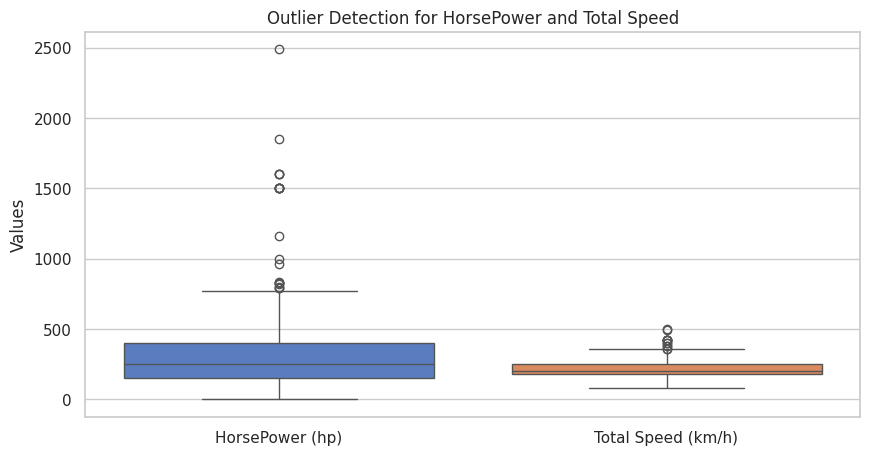

In [58]:
# Clean columns and convert them to numeric values for outlier detection
numeric_hp = df['HorsePower'].str.extract('(\d+)')[0].astype(float)
numeric_speed = df['Total Speed'].str.extract('(\d+)')[0].astype(float)

# Create a temporary DataFrame for plotting
plot_df = pd.DataFrame({
    'HorsePower (hp)': numeric_hp,
    'Total Speed (km/h)': numeric_speed
})

# Plot the boxplots side by side
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df)
plt.title("Outlier Detection for HorsePower and Total Speed")
plt.ylabel("Values")
plt.show()

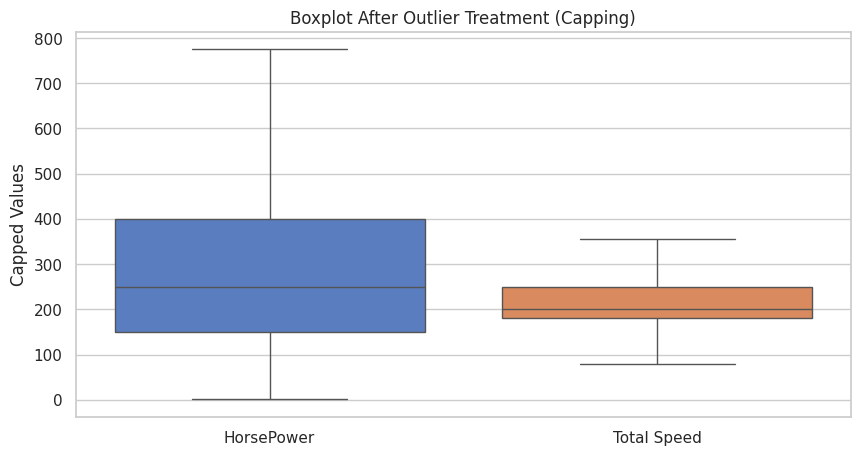

In [63]:
# Plot the updated columns to verify outlier treatment
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['HorsePower', 'Total Speed']])
plt.title("Boxplot After Outlier Treatment (Capping)")
plt.ylabel("Capped Values")
plt.show()

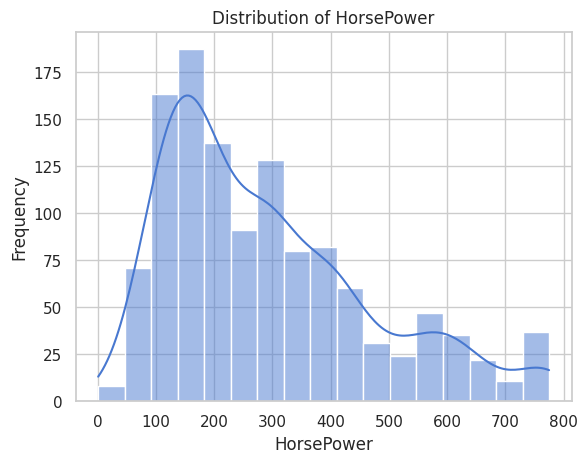

In [64]:
# Univariate Analysis
sns.histplot(df['HorsePower'], kde=True)
plt.title("Distribution of HorsePower")
plt.xlabel("HorsePower")
plt.ylabel("Frequency")
plt.show()

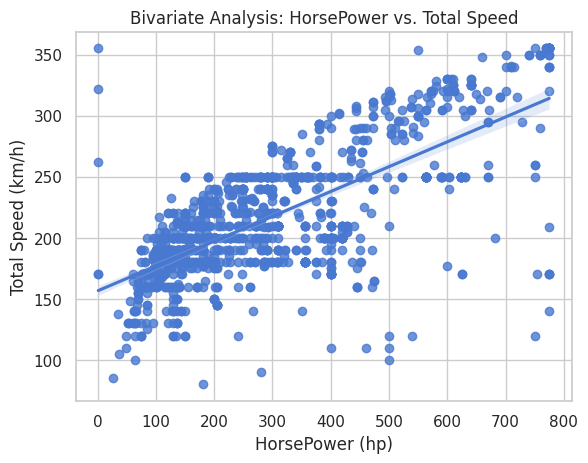

In [66]:
# Bivariate Analysis
sns.regplot(x=df['HorsePower'], y=df['Total Speed'])
plt.title("Bivariate Analysis: HorsePower vs. Total Speed")
plt.xlabel("HorsePower (hp)")
plt.ylabel("Total Speed (km/h)")
plt.show()